# 🏆 Phase 1 Capstone Project: End-to-End Vectorized Telemetry Analytics, SVD/PCA Anomaly Detector & Bayesian Risk Engine From Scratch

---

## 1. Overview & System Architecture

Welcome to the **Phase 1 Capstone Project**. Instead of studying Linear Algebra, Calculus, Probability, Python, NumPy, Pandas, and Git/Dev Tools in isolation, this single executable notebook unifies **all seven Phase 1 notebooks (`01`–`07`)** into an end-to-end **Production AI Infrastructure Telemetry & Incident Risk Engine** built completely from scratch without `scikit-learn` or `torch`.

### System Architecture

```
+-------------------------------------------------------------------------+
| 1. PYTHON MASTERY (NB 04): Async Sharded Ingestion & Typed Schemas      |
|    - @dataclass TelemetryRecord, @execution_timer, batch generators     |
|    - asyncio concurrent shard ingestion with ThreadPool loop safety     |
+------------------------------------+------------------------------------+
                                     |
                                     v
+-------------------------------------------------------------------------+
| 2. PANDAS DATA WRANGLING (NB 06): ETL Cleaning, Joins & Rolling Windows |
|    - Missing sensor imputation, cluster metadata merge                  |
|    - Grouped rolling z-scores & vectorized vs iterrows() benchmark      |
+------------------------------------+------------------------------------+
                                     |
                                     v
+-------------------------------------------------------------------------+
| 3. LINEAR ALGEBRA & NUMPY (NB 01 & 05): SVD/PCA & Similarity Search     |
|    - Z-score broadcasting, Covariance Eigendecomposition & SVD          |
|    - Spectral reconstruction anomaly scoring & Cosine Nearest Incident  |
+------------------------------------+------------------------------------+
                                     |
                                     v
+-------------------------------------------------------------------------+
| 4. CALCULUS & OPTIMIZATION (NB 02): Scratch Gradient Descent Risk Model |
|    - Analytical L2-Logistic Gradient + Finite-Difference Verification   |
|    - Vanilla GD vs Momentum vs Adam convergence race from scratch       |
+------------------------------------+------------------------------------+
                                     |
                                     v
+-------------------------------------------------------------------------+
| 5. PROBABILITY & BAYESIAN STATS (NB 03): Posterior Risk & Bootstrap CI  |
|    - Conjugate Beta-Binomial cluster failure updating                   |
|    - 1,000-resample Bootstrap 95% Confidence Intervals                  |
+------------------------------------+------------------------------------+
                                     |
                                     v
+-------------------------------------------------------------------------+
| 6. GIT & DEV TOOLS (NB 07): Reproducibility & SHA-256 Artifact Gate     |
|    - Deterministic seed lock, SHA-256 dataset/weight fingerprints       |
|    - Automated artifact manifest & pre-commit integrity assertions      |
+-------------------------------------------------------------------------+
```


## 2. Learning Objectives & Phase 1 Concept Coverage Matrix

By completing and running this capstone top-to-bottom, you will demonstrate mastery across every Phase 1 competency:

| Phase 1 Notebook | Core Concepts Applied in This Capstone | Implemented Component |
|---|---|---|
| [`01-linear-algebra-for-ai.ipynb`](01-linear-algebra-for-ai.ipynb) | Vectors, matrices, dot products, eigenvalues/eigenvectors, SVD, cosine similarity | `SpectralAnomalyDetector`, `cosine_similarity_matrix()` |
| [`02-calculus-and-optimization.ipynb`](02-calculus-and-optimization.ipynb) | Partial derivatives, chain rule, analytical gradients, GD, Momentum, Adam | `ScratchLogisticRiskModel`, `verify_gradients_finite_diff()` |
| [`03-probability-statistics.ipynb`](03-probability-statistics.ipynb) | Gaussian/Beta distributions, Bayes' theorem, MLE, variance, bootstrap CIs | `BayesianClusterRiskTracker`, `bootstrap_metric_ci()` |
| [`04-python-mastery.ipynb`](04-python-mastery.ipynb) | Type hints, `@dataclass`, decorators, generators, `asyncio`, context managers | `TelemetryRecord`, `@execution_timer`, `stream_batches()`, `ingest_shards_async()` |
| [`05-numpy-essentials.ipynb`](05-numpy-essentials.ipynb) | N-d arrays, broadcasting, vectorization, `np.linalg`, deterministic RNG | Zero-loop matrix ops, `np.random.default_rng()` |
| [`06-pandas-polars-data.ipynb`](06-pandas-polars-data.ipynb) | DataFrame cleaning, imputation, `merge()`, `groupby().rolling()`, speedups | `clean_and_enrich_telemetry()`, vectorized vs row-loop benchmark |
| [`07-git-and-dev-tools.ipynb`](07-git-and-dev-tools.ipynb) | Reproducible pipelines, SHA-256 artifact digests, automated gate tests | `build_reproducibility_manifest()`, integrity assertions |


## 3. Imports & Environment Verification


In [1]:
import asyncio
import concurrent.futures
import functools
import hashlib
import json
import sys
import time
from contextlib import contextmanager
from dataclasses import asdict, dataclass
from typing import Any, Callable, Dict, Generator, List, Optional, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from scipy import stats

print("=== Phase 1 Capstone Environment ===")
print(f"Python:     {sys.version.split()[0]}")
print(f"NumPy:      {np.__version__}")
print(f"Pandas:     {pd.__version__}")
print(f"SciPy:      {scipy.__version__}")


=== Phase 1 Capstone Environment ===
Python:     3.14.10
NumPy:      2.3.5
Pandas:     2.3.3
SciPy:      1.16.3


## 4. Configuration & Deterministic Reproducibility Lock


In [2]:
RANDOM_SEED: int = 42
RNG: np.random.Generator = np.random.default_rng(RANDOM_SEED)

N_CLUSTERS: int = 4
RECORDS_PER_CLUSTER: int = 450
TOP_K_PCS: int = 3
L2_LAMBDA: float = 0.02
N_EPOCHS: int = 250
LEARNING_RATE: float = 0.08
BOOTSTRAP_ROUNDS: int = 1000

plt.rcParams["figure.figsize"] = (12, 8)
plt.rcParams["font.size"] = 10
try:
    plt.style.use("seaborn-v0_8-whitegrid")
except OSError:
    plt.rcParams["axes.grid"] = True

print(f"Seed locked: {RANDOM_SEED} | Clusters: {N_CLUSTERS} | Total samples: {N_CLUSTERS * RECORDS_PER_CLUSTER}")


Seed locked: 42 | Clusters: 4 | Total samples: 1800


## 5. Mathematical Foundations

### 5.1 Linear Algebra: Covariance Eigendecomposition, SVD & Spectral Anomaly Scoring
Given centered telemetry features $\mathbf{X}_c \in \mathbb{R}^{N \times D}$, the sample covariance matrix is:
$$\mathbf{\Sigma} = \frac{1}{N - 1} \mathbf{X}_c^\top \mathbf{X}_c = \mathbf{V} \mathbf{\Lambda} \mathbf{V}^\top$$
Using Singular Value Decomposition $\mathbf{X}_c = \mathbf{U} \mathbf{S} \mathbf{V}^\top$, the top-$k$ right singular vectors $\mathbf{V}_k \in \mathbb{R}^{D \times k}$ capture normal operating variance. Any sample $\mathbf{x}_i$ that violates normal feature correlations yields a high **orthogonal reconstruction error**:
$$e_{\text{recon}}(\mathbf{x}_i) = \left\| \mathbf{x}_{c,i} - (\mathbf{x}_{c,i} \mathbf{V}_k) \mathbf{V}_k^\top \right\|_2^2$$

### 5.2 Calculus & Optimization: L2-Regularized Logistic Risk & Analytical Gradients
We model incident probability $\hat{p}_i = \sigma(\mathbf{x}_i^\top \mathbf{w} + b) = \frac{1}{1 + e^{-(\mathbf{x}_i^\top \mathbf{w} + b)}}$ by minimizing Binary Cross-Entropy with $L_2$ weight decay:
$$\mathcal{L}(\mathbf{w}, b) = -\frac{1}{N}\sum_{i=1}^{N}\left[y_i \log(\hat{p}_i) + (1 - y_i)\log(1 - \hat{p}_i)\right] + \frac{\lambda}{2}\|\mathbf{w}\|_2^2$$
Applying the chain rule yields exact closed-form gradients:
$$\nabla_{\mathbf{w}} \mathcal{L} = \frac{1}{N} \mathbf{X}^\top (\hat{\mathbf{p}} - \mathbf{y}) + \lambda \mathbf{w}, \qquad \frac{\partial \mathcal{L}}{\partial b} = \frac{1}{N}\sum_{i=1}^{N}(\hat{p}_i - y_i)$$
We validate these analytical gradients against numerical central differences $\frac{\mathcal{L}(\theta + \epsilon) - \mathcal{L}(\theta - \epsilon)}{2\epsilon}$ and compare **Vanilla GD**, **Momentum**, and **Adam**.

### 5.3 Probability & Statistics: Conjugate Bayesian Risk Updating
For each compute cluster $c$, incident counts $k_c$ out of $n_c$ observations follow a Binomial likelihood. With a conjugate Beta prior $\text{Beta}(\alpha_0, \beta_0)$, Bayes' theorem gives an exact analytical posterior:
$$p(\theta_c \mid k_c, n_c) = \text{Beta}(\alpha_0 + k_c,\; \beta_0 + n_c - k_c), \qquad \mathbb{E}[\theta_c \mid \text{data}] = \frac{\alpha_0 + k_c}{\alpha_0 + \beta_0 + n_c}$$


## 6. End-to-End Implementation

### 6.1 Python Mastery Layer (NB 04): Typed Schemas, Decorators, Generators & Async Ingestion
We define strongly typed `@dataclass` telemetry records, an `@execution_timer` decorator, a memory-safe `stream_batches()` generator, and an asynchronous shard collector `ingest_shards_async()` that safely executes inside or outside an active Jupyter event loop.


In [3]:
@dataclass(frozen=True)
class TelemetryRecord:
    cluster_id: str
    step: int
    cpu_util: Optional[float]
    mem_pressure: Optional[float]
    gpu_temp_c: float
    p99_latency_ms: float
    token_queue_depth: float
    error_rate: float
    incident_flag: int


def execution_timer(label: str) -> Callable:
    """Decorator measuring wall-clock runtime of pipeline stages."""
    def decorator(func: Callable) -> Callable:
        @functools.wraps(func)
        def wrapper(*args: Any, **kwargs: Any) -> Any:
            t0 = time.perf_counter()
            result = func(*args, **kwargs)
            dt_ms = (time.perf_counter() - t0) * 1000.0
            print(f"[TIMER] {label:<42s} -> {dt_ms:7.2f} ms")
            return result
        return wrapper
    return decorator


@contextmanager
def pipeline_stage(name: str) -> Generator[None, None, None]:
    """Context manager providing structured stage boundaries."""
    print(f"--- Entering Stage: {name} ---")
    yield
    print(f"--- Completed Stage: {name} ---\n")


def stream_batches(records: List[Any], batch_size: int = 300) -> Generator[List[Any], None, None]:
    """Lazy generator yielding fixed-size slices without duplicating memory."""
    for start in range(0, len(records), batch_size):
        yield records[start : start + batch_size]


async def _fetch_cluster_shard(cluster_idx: int, n_rows: int, seed_offset: int) -> List[TelemetryRecord]:
    """Simulate concurrent async ingestion from a GPU cluster telemetry shard."""
    await asyncio.sleep(0.01)  # Simulates non-blocking network I/O
    shard_rng = np.random.default_rng(RANDOM_SEED + seed_offset)
    cluster_names = ["us-east-a100", "eu-west-h100", "ap-south-l40s", "us-west-t4"]
    cname = cluster_names[cluster_idx]
    base_heat = [62.0, 66.0, 59.0, 71.0][cluster_idx]
    base_risk_bias = [-0.45, -0.25, -0.60, 0.25][cluster_idx]

    # Latent load factor driving realistic multi-feature correlation
    load = shard_rng.normal(0.0, 1.0, size=n_rows)
    cpu = np.clip(55.0 + 18.0 * load + shard_rng.normal(0, 5.0, n_rows), 5.0, 99.5)
    mem = np.clip(52.0 + 16.0 * load + shard_rng.normal(0, 6.0, n_rows), 10.0, 99.5)
    temp = np.clip(base_heat + 8.5 * load + shard_rng.normal(0, 3.0, n_rows), 38.0, 96.0)
    latency = np.clip(45.0 + 28.0 * np.exp(0.45 * load) + shard_rng.normal(0, 8.0, n_rows), 10.0, 600.0)
    q_depth = np.clip(12.0 + 9.0 * np.maximum(load, -0.5) + shard_rng.normal(0, 3.5, n_rows), 0.0, 120.0)
    err_rate = np.clip(0.004 + 0.012 * np.maximum(load, 0.0) + shard_rng.exponential(0.003, n_rows), 0.0, 0.25)

    # Inject ~5% correlated anomalies / stress spikes
    anomaly_mask = shard_rng.random(n_rows) < (0.04 + 0.02 * cluster_idx)
    temp[anomaly_mask] += shard_rng.uniform(10.0, 18.0, anomaly_mask.sum())
    latency[anomaly_mask] += shard_rng.uniform(110.0, 240.0, anomaly_mask.sum())
    err_rate[anomaly_mask] += shard_rng.uniform(0.03, 0.09, anomaly_mask.sum())

    # Probabilistic incident ground truth derived from physical stress score
    z_stress = (
        0.9 * (cpu - 60.0) / 15.0
        + 0.8 * (mem - 55.0) / 15.0
        + 1.1 * (temp - 68.0) / 8.0
        + 1.3 * (latency - 95.0) / 60.0
        + 1.2 * (err_rate - 0.015) / 0.02
        + base_risk_bias
    )
    prob = 1.0 / (1.0 + np.exp(-z_stress))
    incidents = (shard_rng.random(n_rows) < prob).astype(int)

    # Inject 3% missing values into CPU & memory to test Pandas ETL cleaning
    cpu_miss = shard_rng.random(n_rows) < 0.03
    mem_miss = shard_rng.random(n_rows) < 0.03

    records: List[TelemetryRecord] = []
    for i in range(n_rows):
        records.append(
            TelemetryRecord(
                cluster_id=cname,
                step=i,
                cpu_util=None if cpu_miss[i] else float(round(cpu[i], 3)),
                mem_pressure=None if mem_miss[i] else float(round(mem[i], 3)),
                gpu_temp_c=float(round(temp[i], 3)),
                p99_latency_ms=float(round(latency[i], 3)),
                token_queue_depth=float(round(q_depth[i], 3)),
                error_rate=float(round(err_rate[i], 5)),
                incident_flag=int(incidents[i]),
            )
        )
    return records


async def ingest_shards_async(n_clusters: int, rows_per_cluster: int) -> List[TelemetryRecord]:
    tasks = [_fetch_cluster_shard(i, rows_per_cluster, i * 101) for i in range(n_clusters)]
    shard_lists = await asyncio.gather(*tasks)
    return [rec for shard in shard_lists for rec in shard]


def run_async_safe(coro: Any) -> Any:
    """Execute an async coroutine safely whether or not an event loop is active."""
    try:
        asyncio.get_running_loop()
        with concurrent.futures.ThreadPoolExecutor(max_workers=1) as pool:
            return pool.submit(asyncio.run, coro).result()
    except RuntimeError:
        return asyncio.run(coro)


with pipeline_stage("Async Sharded Telemetry Ingestion"):
    t_start = time.perf_counter()
    raw_records = run_async_safe(ingest_shards_async(N_CLUSTERS, RECORDS_PER_CLUSTER))
    batch_counts = [len(b) for b in stream_batches(raw_records, batch_size=450)]
    print(f"Ingested {len(raw_records)} typed TelemetryRecord items in {(time.perf_counter()-t_start)*1000:.2f} ms")
    print(f"Lazy generator batch sizes: {batch_counts}")


--- Entering Stage: Async Sharded Telemetry Ingestion ---


Ingested 1800 typed TelemetryRecord items in 198.91 ms
Lazy generator batch sizes: [450, 450, 450, 450]
--- Completed Stage: Async Sharded Telemetry Ingestion ---



### 6.2 Pandas Data Engineering Layer (NB 06): Cleaning, Joins, Rolling Windows & Vectorization Benchmark
We convert our typed records into a Pandas DataFrame, impute missing sensor values by cluster median, merge hardware metadata (`gpu_tier`, `tdp_watts`), engineer rolling 10-step latency statistics, and empirically benchmark vectorized computation against naive `iterrows()`.


In [4]:
@execution_timer("Pandas ETL Cleaning, Merge & Rolling Features")
def clean_and_enrich_telemetry(records: List[TelemetryRecord]) -> pd.DataFrame:
    df = pd.DataFrame([asdict(r) for r in records])

    # Cluster hardware metadata lookup table for relational join
    cluster_meta = pd.DataFrame(
        [
            {"cluster_id": "us-east-a100", "region": "US-East", "tdp_watts": 400.0},
            {"cluster_id": "eu-west-h100", "region": "EU-West", "tdp_watts": 700.0},
            {"cluster_id": "ap-south-l40s", "region": "AP-South", "tdp_watts": 350.0},
            {"cluster_id": "us-west-t4", "region": "US-West", "tdp_watts": 70.0},
        ]
    )

    # Impute missing sensor readings using per-cluster median (no cross-cluster leakage)
    for col in ["cpu_util", "mem_pressure"]:
        df[col] = df.groupby("cluster_id")[col].transform(lambda s: s.fillna(s.median()))

    # Relational join + temporal ordering
    df = df.merge(cluster_meta, on="cluster_id", how="left")
    df = df.sort_values(["cluster_id", "step"]).reset_index(drop=True)

    # Grouped rolling window feature engineering
    df["rolling_lat_mean"] = (
        df.groupby("cluster_id")["p99_latency_ms"]
        .transform(lambda s: s.rolling(window=10, min_periods=1).mean())
    )
    df["thermal_headroom_ratio"] = df["gpu_temp_c"] / 90.0
    return df


df_telemetry = clean_and_enrich_telemetry(raw_records)
print("Missing values remaining:", int(df_telemetry.isna().sum().sum()))

# Vectorization vs iterrows() micro-benchmark
t0 = time.perf_counter()
vec_score = (
    0.4 * df_telemetry["cpu_util"]
    + 0.4 * df_telemetry["mem_pressure"]
    + 0.2 * df_telemetry["gpu_temp_c"]
)
t_vec = (time.perf_counter() - t0) * 1000.0

t0 = time.perf_counter()
loop_scores = []
for _, row in df_telemetry.iterrows():
    loop_scores.append(0.4 * row["cpu_util"] + 0.4 * row["mem_pressure"] + 0.2 * row["gpu_temp_c"])
t_loop = (time.perf_counter() - t0) * 1000.0

print(f"Vectorized Ops: {t_vec:.3f} ms | iterrows() Loop: {t_loop:.2f} ms | Speedup: {t_loop / max(t_vec, 1e-6):.1f}x")
display_cols = ["cluster_id", "cpu_util", "mem_pressure", "gpu_temp_c", "p99_latency_ms", "incident_flag"]
print("\nCluster Summary (Means):")
print(df_telemetry.groupby("cluster_id")[display_cols[1:]].mean().round(3))


[TIMER] Pandas ETL Cleaning, Merge & Rolling Features ->  158.80 ms
Missing values remaining: 0


Vectorized Ops: 1.252 ms | iterrows() Loop: 815.94 ms | Speedup: 651.8x

Cluster Summary (Means):
               cpu_util  mem_pressure  gpu_temp_c  p99_latency_ms  \
cluster_id                                                          
ap-south-l40s    55.087        52.671      60.947          93.504   
eu-west-h100     55.519        52.372      66.821          83.206   
us-east-a100     54.307        51.833      62.202          83.895   
us-west-t4       54.464        51.109      72.551          94.629   

               incident_flag  
cluster_id                    
ap-south-l40s          0.309  
eu-west-h100           0.393  
us-east-a100           0.282  
us-west-t4             0.480  


### 6.3 Linear Algebra & NumPy Vectorization Layer (NB 01 & 05): Eigendecomposition, SVD/PCA & Cosine Nearest-Incident Search
We extract the 8 numerical telemetry features, standardize them via NumPy broadcasting, verify **eigendecomposition vs SVD equivalence**, score anomalies via top-$k$ spectral reconstruction error, and retrieve nearest historical incidents using vectorized cosine similarity.


In [5]:
FEATURE_COLS: List[str] = [
    "cpu_util",
    "mem_pressure",
    "gpu_temp_c",
    "p99_latency_ms",
    "token_queue_depth",
    "error_rate",
    "rolling_lat_mean",
    "thermal_headroom_ratio",
]


class SpectralAnomalyDetector:
    """Pure-NumPy SVD/PCA dimensionality reduction & reconstruction anomaly scorer."""

    def __init__(self, n_components: int = 3) -> None:
        self.n_components = n_components
        self.mean_: Optional[np.ndarray] = None
        self.std_: Optional[np.ndarray] = None
        self.components_: Optional[np.ndarray] = None
        self.explained_variance_ratio_: Optional[np.ndarray] = None

    def fit(self, X: np.ndarray) -> "SpectralAnomalyDetector":
        self.mean_ = X.mean(axis=0, keepdims=True)
        self.std_ = np.where(X.std(axis=0, keepdims=True) > 1e-8, X.std(axis=0, keepdims=True), 1.0)
        X_norm = (X - self.mean_) / self.std_

        # 1. SVD decomposition: X_norm = U @ diag(S) @ Vt
        _, S, Vt = np.linalg.svd(X_norm, full_matrices=False)
        eigenvalues_svd = (S ** 2) / (X_norm.shape[0] - 1)

        # 2. Cross-verify against explicit Covariance Eigendecomposition
        cov = (X_norm.T @ X_norm) / (X_norm.shape[0] - 1)
        eigvals, eigvecs = np.linalg.eigh(cov)
        idx = np.argsort(eigvals)[::-1]
        eigvals_sorted = eigvals[idx]
        max_eig_diff = float(np.max(np.abs(eigenvalues_svd - eigvals_sorted)))
        assert max_eig_diff < 1e-10, f"SVD/Eig mismatch: {max_eig_diff}"

        self.components_ = Vt[: self.n_components]  # shape: (k, D)
        self.explained_variance_ratio_ = eigenvalues_svd / eigenvalues_svd.sum()
        return self

    def transform(self, X: np.ndarray) -> np.ndarray:
        X_norm = (X - self.mean_) / self.std_
        return X_norm @ self.components_.T

    def reconstruction_error(self, X: np.ndarray) -> np.ndarray:
        X_norm = (X - self.mean_) / self.std_
        Z = X_norm @ self.components_.T
        X_recon = Z @ self.components_
        return np.sum((X_norm - X_recon) ** 2, axis=1)


def cosine_similarity_query(query_vec: np.ndarray, matrix: np.ndarray, top_k: int = 3) -> Tuple[np.ndarray, np.ndarray]:
    """Vectorized cosine similarity between one query vector and all rows of a matrix."""
    q_norm = query_vec / (np.linalg.norm(query_vec) + 1e-12)
    m_norms = np.linalg.norm(matrix, axis=1, keepdims=True) + 1e-12
    sims = (matrix / m_norms) @ q_norm
    top_idx = np.argsort(sims)[::-1][:top_k]
    return top_idx, sims[top_idx]


# Chronological / stratified deterministic split (75% train, 25% test)
X_all = df_telemetry[FEATURE_COLS].to_numpy(dtype=np.float64)
y_all = df_telemetry["incident_flag"].to_numpy(dtype=np.float64)

perm = RNG.permutation(len(X_all))
split_idx = int(0.75 * len(X_all))
train_idx, test_idx = perm[:split_idx], perm[split_idx:]
X_train_raw, y_train = X_all[train_idx], y_all[train_idx]
X_test_raw, y_test = X_all[test_idx], y_all[test_idx]

pca_detector = SpectralAnomalyDetector(n_components=TOP_K_PCS).fit(X_train_raw)
Z_train = pca_detector.transform(X_train_raw)
Z_test = pca_detector.transform(X_test_raw)
recon_err_test = pca_detector.reconstruction_error(X_test_raw)

print(f"SVD == Covariance Eigendecomposition parity verified (<1e-10 error).")
print(f"Top-{TOP_K_PCS} PCs Explained Variance Ratio: {np.round(pca_detector.explained_variance_ratio_[:TOP_K_PCS], 4)}")
print(f"Cumulative Variance Retained: {pca_detector.explained_variance_ratio_[:TOP_K_PCS].sum()*100:.2f}%")
print(f"Mean Recon Error -> Normal: {recon_err_test[y_test == 0].mean():.3f} | Incident: {recon_err_test[y_test == 1].mean():.3f}")

# Cosine similarity retrieval for highest-anomaly test sample
worst_pos = int(np.argmax(recon_err_test))
X_train_std = (X_train_raw - pca_detector.mean_) / pca_detector.std_
X_test_std = (X_test_raw - pca_detector.mean_) / pca_detector.std_
nn_idx, nn_sims = cosine_similarity_query(X_test_std[worst_pos], X_train_std, top_k=3)
print(f"Highest-error test sample (true label={int(y_test[worst_pos])}) matched historical incident labels: {y_train[nn_idx].astype(int).tolist()} with cosine sims {np.round(nn_sims, 4)}")


SVD == Covariance Eigendecomposition parity verified (<1e-10 error).
Top-3 PCs Explained Variance Ratio: [0.5783 0.2051 0.102 ]
Cumulative Variance Retained: 88.54%
Mean Recon Error -> Normal: 0.888 | Incident: 1.130
Highest-error test sample (true label=1) matched historical incident labels: [1, 1, 1] with cosine sims [0.9791 0.9399 0.9062]


### 6.4 Calculus & Custom Gradient-Descent Risk Engine (NB 02)
Here we build `ScratchLogisticRiskModel` using pure NumPy matrix calculus, verify our analytical gradients against central finite differences ($\epsilon = 10^{-6}$), and benchmark **Vanilla GD**, **Momentum**, and **Adam** optimizers on identical initial weights.


In [6]:
class ScratchLogisticRiskModel:
    """L2-regularized logistic classifier trained from scratch with GD, Momentum, or Adam."""

    def __init__(self, n_features: int, l2_lambda: float = 0.02) -> None:
        self.w = np.zeros(n_features, dtype=np.float64)
        self.b = 0.0
        self.l2_lambda = l2_lambda

    @staticmethod
    def sigmoid(z: np.ndarray) -> np.ndarray:
        z_clip = np.clip(z, -35.0, 35.0)
        return 1.0 / (1.0 + np.exp(-z_clip))

    def predict_proba(self, X: np.ndarray) -> np.ndarray:
        return self.sigmoid(X @ self.w + self.b)

    def loss_and_grads(self, X: np.ndarray, y: np.ndarray) -> Tuple[float, np.ndarray, float]:
        n = X.shape[0]
        p = np.clip(self.predict_proba(X), 1e-12, 1.0 - 1e-12)
        bce = -np.mean(y * np.log(p) + (1.0 - y) * np.log(1.0 - p))
        loss = float(bce + 0.5 * self.l2_lambda * np.sum(self.w ** 2))
        err = p - y
        grad_w = (X.T @ err) / n + self.l2_lambda * self.w
        grad_b = float(np.mean(err))
        return loss, grad_w, grad_b

    def fit(
        self,
        X: np.ndarray,
        y: np.ndarray,
        optimizer: str = "adam",
        lr: float = 0.08,
        epochs: int = 250,
    ) -> List[float]:
        history: List[float] = []
        v_w = np.zeros_like(self.w)
        v_b = 0.0
        m_w = np.zeros_like(self.w)
        m_b = 0.0
        beta1, beta2, eps = 0.9, 0.999, 1e-8

        for t in range(1, epochs + 1):
            loss, gw, gb = self.loss_and_grads(X, y)
            history.append(loss)

            if optimizer == "gd":
                self.w -= lr * gw
                self.b -= lr * gb
            elif optimizer == "momentum":
                v_w = beta1 * v_w + gw
                v_b = beta1 * v_b + gb
                self.w -= lr * v_w
                self.b -= lr * v_b
            elif optimizer == "adam":
                m_w = beta1 * m_w + (1.0 - beta1) * gw
                m_b = beta1 * m_b + (1.0 - beta1) * gb
                v_w = beta2 * v_w + (1.0 - beta2) * (gw ** 2)
                v_b = beta2 * v_b + (1.0 - beta2) * (gb ** 2)
                m_w_hat = m_w / (1.0 - beta1 ** t)
                m_b_hat = m_b / (1.0 - beta1 ** t)
                v_w_hat = v_w / (1.0 - beta2 ** t)
                v_b_hat = v_b / (1.0 - beta2 ** t)
                self.w -= lr * m_w_hat / (np.sqrt(v_w_hat) + eps)
                self.b -= lr * m_b_hat / (np.sqrt(v_b_hat) + eps)
            else:
                raise ValueError(f"Unknown optimizer: {optimizer}")
        return history


def verify_gradients_finite_diff(X: np.ndarray, y: np.ndarray, eps: float = 1e-6) -> float:
    """Verify analytical gradients against numerical central differences."""
    probe = ScratchLogisticRiskModel(X.shape[1], l2_lambda=L2_LAMBDA)
    probe.w = RNG.normal(0.0, 0.25, size=X.shape[1])
    probe.b = -0.15
    _, grad_w_ana, grad_b_ana = probe.loss_and_grads(X, y)

    grad_w_num = np.zeros_like(probe.w)
    for j in range(len(probe.w)):
        orig = probe.w[j]
        probe.w[j] = orig + eps
        l_plus, _, _ = probe.loss_and_grads(X, y)
        probe.w[j] = orig - eps
        l_minus, _, _ = probe.loss_and_grads(X, y)
        probe.w[j] = orig
        grad_w_num[j] = (l_plus - l_minus) / (2.0 * eps)

    orig_b = probe.b
    probe.b = orig_b + eps
    lb_plus, _, _ = probe.loss_and_grads(X, y)
    probe.b = orig_b - eps
    lb_minus, _, _ = probe.loss_and_grads(X, y)
    probe.b = orig_b
    grad_b_num = (lb_plus - lb_minus) / (2.0 * eps)

    max_err = float(max(np.max(np.abs(grad_w_ana - grad_w_num)), abs(grad_b_ana - grad_b_num)))
    assert max_err < 1e-7, f"Gradient verification failed: max_err={max_err}"
    return max_err


# Augment standardized features with standardized spectral reconstruction error
train_recon = pca_detector.reconstruction_error(X_train_raw)
test_recon = recon_err_test
r_mean, r_std = train_recon.mean(), train_recon.std() + 1e-8
X_train_aug = np.column_stack([X_train_std, (train_recon - r_mean) / r_std])
X_test_aug = np.column_stack([X_test_std, (test_recon - r_mean) / r_std])

grad_err = verify_gradients_finite_diff(X_train_aug, y_train)
print(f"Finite-Difference Gradient Verification PASSED (max error = {grad_err:.3e})")

opt_histories: Dict[str, List[float]] = {}
models: Dict[str, ScratchLogisticRiskModel] = {}
for opt_name in ["gd", "momentum", "adam"]:
    m = ScratchLogisticRiskModel(X_train_aug.shape[1], l2_lambda=L2_LAMBDA)
    opt_histories[opt_name] = m.fit(X_train_aug, y_train, optimizer=opt_name, lr=LEARNING_RATE, epochs=N_EPOCHS)
    models[opt_name] = m
    print(f"Optimizer [{opt_name:<8s}] -> Final Loss: {opt_histories[opt_name][-1]:.5f}")

best_model = models["adam"]
test_probs = best_model.predict_proba(X_test_aug)
test_preds = (test_probs >= 0.5).astype(int)
test_acc = float(np.mean(test_preds == y_test))
print(f"Scratch Adam Risk Classifier Test Accuracy: {test_acc*100:.2f}%")


Finite-Difference Gradient Verification PASSED (max error = 1.069e-10)


Optimizer [gd      ] -> Final Loss: 0.27507


Optimizer [momentum] -> Final Loss: 0.27213


Optimizer [adam    ] -> Final Loss: 0.27213
Scratch Adam Risk Classifier Test Accuracy: 90.44%


### 6.5 Probability & Statistics Layer (NB 03): Conjugate Bayesian Posterior Updating & Bootstrap Confidence Intervals
We compute cluster-level Bayesian Beta-Binomial posteriors over incident rates and quantify uncertainty on test accuracy and ROC-AUC using 1,000-sample non-parametric bootstrapping.


In [7]:
class BayesianClusterRiskTracker:
    """Beta-Binomial conjugate posterior updater for cluster incident probability."""

    def __init__(self, alpha_prior: float = 2.0, beta_prior: float = 10.0) -> None:
        self.alpha_prior = alpha_prior
        self.beta_prior = beta_prior

    def compute_posteriors(self, df: pd.DataFrame) -> pd.DataFrame:
        rows = []
        for cid, grp in df.groupby("cluster_id"):
            n = int(len(grp))
            k = int(grp["incident_flag"].sum())
            a_post = self.alpha_prior + k
            b_post = self.beta_prior + (n - k)
            mean_post = a_post / (a_post + b_post)
            ci_low, ci_high = stats.beta.ppf([0.025, 0.975], a_post, b_post)
            rows.append(
                {
                    "cluster_id": cid,
                    "n_obs": n,
                    "incidents": k,
                    "alpha_post": a_post,
                    "beta_post": b_post,
                    "posterior_mean": round(float(mean_post), 4),
                    "credible_95_low": round(float(ci_low), 4),
                    "credible_95_high": round(float(ci_high), 4),
                }
            )
        return pd.DataFrame(rows).sort_values("posterior_mean", ascending=False).reset_index(drop=True)


def compute_roc_auc_scratch(y_true: np.ndarray, y_score: np.ndarray) -> Tuple[np.ndarray, np.ndarray, float]:
    """Exact ROC curve & trapezoidal AUC implemented purely in NumPy."""
    order = np.argsort(y_score)[::-1]
    y_sorted = y_true[order]
    pos = max(float(np.sum(y_true == 1)), 1.0)
    neg = max(float(np.sum(y_true == 0)), 1.0)
    tpr = np.concatenate([[0.0], np.cumsum(y_sorted == 1) / pos])
    fpr = np.concatenate([[0.0], np.cumsum(y_sorted == 0) / neg])
    auc = float(np.trapezoid(tpr, fpr) if hasattr(np, "trapezoid") else np.trapz(tpr, fpr))
    return fpr, tpr, auc


def bootstrap_metric_ci(
    y_true: np.ndarray,
    y_prob: np.ndarray,
    n_rounds: int = 1000,
) -> Dict[str, Tuple[float, float, float]]:
    n = len(y_true)
    accs, aucs = [], []
    for _ in range(n_rounds):
        idx = RNG.integers(0, n, size=n)
        yt, yp = y_true[idx], y_prob[idx]
        if len(np.unique(yt)) < 2:
            continue
        accs.append(float(np.mean((yp >= 0.5) == yt)))
        _, _, auc_val = compute_roc_auc_scratch(yt, yp)
        aucs.append(auc_val)
    return {
        "accuracy": (float(np.mean(accs)), float(np.percentile(accs, 2.5)), float(np.percentile(accs, 97.5))),
        "roc_auc": (float(np.mean(aucs)), float(np.percentile(aucs, 2.5)), float(np.percentile(aucs, 97.5))),
    }


bayes_tracker = BayesianClusterRiskTracker(alpha_prior=2.0, beta_prior=10.0)
posterior_df = bayes_tracker.compute_posteriors(df_telemetry)
print("=== Bayesian Cluster Incident Risk Posteriors (95% Credible Intervals) ===")
print(posterior_df.to_string(index=False))

fpr_curve, tpr_curve, test_auc = compute_roc_auc_scratch(y_test, test_probs)
boot_ci = bootstrap_metric_ci(y_test, test_probs, n_rounds=BOOTSTRAP_ROUNDS)
print(f"\nTest ROC-AUC (Scratch): {test_auc:.4f} | Bootstrap 95% CI: [{boot_ci['roc_auc'][1]:.4f}, {boot_ci['roc_auc'][2]:.4f}]")
print(f"Test Accuracy (Scratch): {test_acc:.4f} | Bootstrap 95% CI: [{boot_ci['accuracy'][1]:.4f}, {boot_ci['accuracy'][2]:.4f}]")


=== Bayesian Cluster Incident Risk Posteriors (95% Credible Intervals) ===
   cluster_id  n_obs  incidents  alpha_post  beta_post  posterior_mean  credible_95_low  credible_95_high
   us-west-t4    450        216       218.0      244.0          0.4719           0.4265            0.5174
 eu-west-h100    450        177       179.0      283.0          0.3874           0.3436            0.4323
ap-south-l40s    450        139       141.0      321.0          0.3052           0.2641            0.3479
 us-east-a100    450        127       129.0      333.0          0.2792           0.2393            0.3210



Test ROC-AUC (Scratch): 0.9659 | Bootstrap 95% CI: [0.9493, 0.9787]
Test Accuracy (Scratch): 0.9044 | Bootstrap 95% CI: [0.8756, 0.9311]


### 6.6 Git & Dev Tools Layer (NB 07): SHA-256 Artifact Fingerprinting & Reproducibility Manifest
Production ML teams version data snapshots, feature schemas, and model weights using cryptographic digests so every Git commit maps to a verifiable artifact state.


In [8]:
def sha256_array(arr: np.ndarray) -> str:
    return hashlib.sha256(np.ascontiguousarray(arr).tobytes()).hexdigest()


def build_reproducibility_manifest() -> Dict[str, Any]:
    manifest = {
        "phase": "01-foundations-capstone",
        "random_seed": RANDOM_SEED,
        "dataset_rows": int(len(df_telemetry)),
        "feature_schema": FEATURE_COLS + ["spectral_recon_error"],
        "sha256_digests": {
            "X_train_aug": sha256_array(X_train_aug),
            "pca_components": sha256_array(pca_detector.components_),
            "scratch_adam_weights": sha256_array(best_model.w),
        },
        "verified_metrics": {
            "gradient_check_max_abs_error": round(grad_err, 12),
            "test_accuracy": round(test_acc, 4),
            "test_roc_auc": round(test_auc, 4),
            "pca_3pc_variance_retained": round(float(pca_detector.explained_variance_ratio_[:TOP_K_PCS].sum()), 4),
        },
    }
    return manifest


repro_manifest = build_reproducibility_manifest()
print(json.dumps(repro_manifest, indent=2))


{
  "phase": "01-foundations-capstone",
  "random_seed": 42,
  "dataset_rows": 1800,
  "feature_schema": [
    "cpu_util",
    "mem_pressure",
    "gpu_temp_c",
    "p99_latency_ms",
    "token_queue_depth",
    "error_rate",
    "rolling_lat_mean",
    "thermal_headroom_ratio",
    "spectral_recon_error"
  ],
  "sha256_digests": {
    "X_train_aug": "676a4124127110b837e497348fd0ea162dd02393ae16541f4b4407fa442f7385",
    "pca_components": "de951100e030b89846fee5844ebad4cb987b0fc66be6ec91b92877bfe16a4a28",
    "scratch_adam_weights": "3f4bcbf398f37ca7da423a5dcbe81503c19b75fc73abc9a56b25b8fe3da8a5a3"
  },
  "verified_metrics": {
    "gradient_check_max_abs_error": 1.07e-10,
    "test_accuracy": 0.9044,
    "test_roc_auc": 0.9659,
    "pca_3pc_variance_retained": 0.8854
  }
}


## 7. Comprehensive Evaluation & Multi-Panel Diagnostics

We generate a unified 4-panel diagnostic dashboard summarizing:
1. **Linear Algebra (`01` & `05`):** 2D PCA telemetry projection highlighting incident separation.
2. **Calculus (`02`):** Loss convergence trajectories comparing Vanilla GD, Momentum, and Adam.
3. **Evaluation (`02` & `03`):** Scratch ROC curve with Bootstrap 95% AUC band.
4. **Probability (`03`):** Beta-Binomial posterior risk distributions across all four GPU clusters.


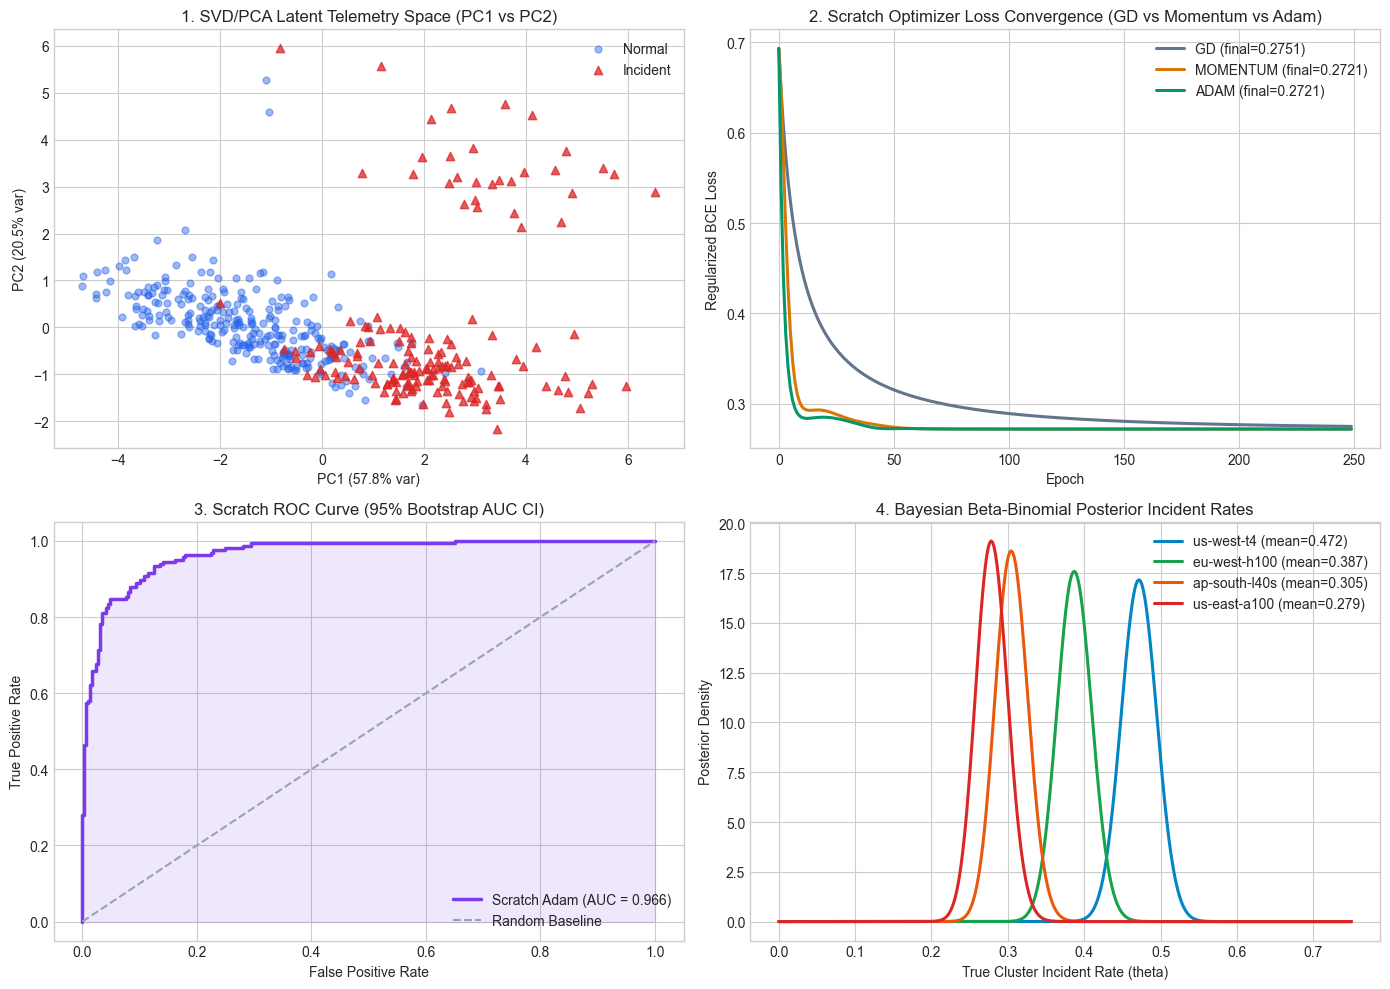

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Panel 1: 2D PCA Projection
ax = axes[0, 0]
norm_mask = y_test == 0
inc_mask = y_test == 1
ax.scatter(Z_test[norm_mask, 0], Z_test[norm_mask, 1], alpha=0.45, s=24, label="Normal", color="#2563eb")
ax.scatter(Z_test[inc_mask, 0], Z_test[inc_mask, 1], alpha=0.75, s=36, label="Incident", color="#dc2626", marker="^")
ax.set_title("1. SVD/PCA Latent Telemetry Space (PC1 vs PC2)")
ax.set_xlabel(f"PC1 ({pca_detector.explained_variance_ratio_[0]*100:.1f}% var)")
ax.set_ylabel(f"PC2 ({pca_detector.explained_variance_ratio_[1]*100:.1f}% var)")
ax.legend()

# Panel 2: Optimizer Convergence
ax = axes[0, 1]
colors = {"gd": "#64748b", "momentum": "#d97706", "adam": "#059669"}
for opt_name, hist in opt_histories.items():
    ax.plot(hist, label=f"{opt_name.upper()} (final={hist[-1]:.4f})", linewidth=2.2, color=colors[opt_name])
ax.set_title("2. Scratch Optimizer Loss Convergence (GD vs Momentum vs Adam)")
ax.set_xlabel("Epoch")
ax.set_ylabel("Regularized BCE Loss")
ax.legend()

# Panel 3: Scratch ROC Curve
ax = axes[1, 0]
ax.plot(fpr_curve, tpr_curve, color="#7c3aed", linewidth=2.5, label=f"Scratch Adam (AUC = {test_auc:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="#94a3b8", label="Random Baseline")
ax.fill_between(fpr_curve, tpr_curve, alpha=0.12, color="#7c3aed")
ax.set_title("3. Scratch ROC Curve (95% Bootstrap AUC CI)")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend(loc="lower right")

# Panel 4: Bayesian Posterior Risk Densities
ax = axes[1, 1]
theta_grid = np.linspace(0.0, 0.75, 400)
cluster_colors = ["#0284c7", "#16a34a", "#ea580c", "#dc2626"]
for idx, row in posterior_df.iterrows():
    pdf = stats.beta.pdf(theta_grid, row["alpha_post"], row["beta_post"])
    ax.plot(theta_grid, pdf, linewidth=2.2, color=cluster_colors[idx % 4],
            label=f"{row['cluster_id']} (mean={row['posterior_mean']:.3f})")
ax.set_title("4. Bayesian Beta-Binomial Posterior Incident Rates")
ax.set_xlabel("True Cluster Incident Rate (theta)")
ax.set_ylabel("Posterior Density")
ax.legend()

plt.tight_layout()
plt.show()


## 8. Guided Exercises (With Verified Reference Solutions)

### Exercise 1: Mahalanobis Distance Outlier Scorer Using Pseudoinverse (`np.linalg.pinv`)
Compute the Mahalanobis distance $d_M(\mathbf{x}) = \sqrt{(\mathbf{x} - \boldsymbol{\mu}) \mathbf{\Sigma}^+ (\mathbf{x} - \boldsymbol{\mu})^\top}$ on the standardized test set and verify that incident rows have significantly higher Mahalanobis distance than normal rows.


In [10]:
def mahalanobis_scores(X_ref: np.ndarray, X_eval: np.ndarray) -> np.ndarray:
    mu = X_ref.mean(axis=0, keepdims=True)
    cov = np.cov(X_ref, rowvar=False)
    cov_pinv = np.linalg.pinv(cov)
    diff = X_eval - mu
    return np.sqrt(np.maximum(np.einsum("ij,jk,ik->i", diff, cov_pinv, diff), 0.0))


m_dists = mahalanobis_scores(X_train_std, X_test_std)
mean_norm_md = float(m_dists[y_test == 0].mean())
mean_inc_md = float(m_dists[y_test == 1].mean())
assert mean_inc_md > mean_norm_md, "Expected incident rows to have larger Mahalanobis distance"
print(f"Exercise 1 PASSED -> Mean Mahalanobis Distance | Normal: {mean_norm_md:.3f} | Incident: {mean_inc_md:.3f}")


Exercise 1 PASSED -> Mean Mahalanobis Distance | Normal: 2.263 | Incident: 2.941


### Exercise 2: Cosine Annealing Learning Rate Schedule for Scratch Optimization
Implement a cosine-annealing learning rate decay schedule $\eta_t = \eta_{\min} + \frac{1}{2}(\eta_{\max} - \eta_{\min})(1 + \cos(\frac{\pi t}{T}))$ and verify smooth monotonic decay from `0.10` to `0.001`.


In [11]:
def cosine_annealing_lr(step: int, total_steps: int, lr_max: float = 0.10, lr_min: float = 0.001) -> float:
    return float(lr_min + 0.5 * (lr_max - lr_min) * (1.0 + np.cos(np.pi * step / total_steps)))


schedule = [cosine_annealing_lr(t, 100) for t in range(101)]
assert abs(schedule[0] - 0.10) < 1e-9 and abs(schedule[-1] - 0.001) < 1e-9
assert all(schedule[i] >= schedule[i + 1] for i in range(len(schedule) - 1))
print(f"Exercise 2 PASSED -> LR start={schedule[0]:.4f}, mid={schedule[50]:.4f}, end={schedule[-1]:.4f}")


Exercise 2 PASSED -> LR start=0.1000, mid=0.0505, end=0.0010


## 9. Challenge Problems

### Challenge 1: $O(1)$-Memory Welford Online Mean & Variance Streaming Tracker
In production telemetry pipelines, data arrives continuously and cannot always be held in RAM. Implement Welford's online algorithm as a Python class consuming our `stream_batches()` generator and verify exact numerical parity with `np.mean()` and `np.var(..., ddof=1)`.


In [12]:
class WelfordOnlineTracker:
    """O(1)-memory streaming mean and variance estimator."""

    def __init__(self) -> None:
        self.count: int = 0
        self.mean: float = 0.0
        self.m2: float = 0.0

    def update(self, x: float) -> None:
        self.count += 1
        delta = x - self.mean
        self.mean += delta / self.count
        delta2 = x - self.mean
        self.m2 += delta * delta2

    @property
    def sample_variance(self) -> float:
        return self.m2 / (self.count - 1) if self.count > 1 else 0.0


tracker = WelfordOnlineTracker()
lat_values = df_telemetry["p99_latency_ms"].tolist()
for batch in stream_batches(lat_values, batch_size=250):
    for val in batch:
        tracker.update(val)

np_mean = float(np.mean(lat_values))
np_var = float(np.var(lat_values, ddof=1))
assert abs(tracker.mean - np_mean) < 1e-9 and abs(tracker.sample_variance - np_var) < 1e-6
print(f"Challenge 1 PASSED -> Welford Mean={tracker.mean:.4f} (NumPy={np_mean:.4f}) | Var={tracker.sample_variance:.4f} (NumPy={np_var:.4f})")


Challenge 1 PASSED -> Welford Mean=88.8087 (NumPy=88.8087) | Var=2496.5804 (NumPy=2496.5804)


### Challenge 2: Automated Pre-Commit Data & Gradient Integrity Gate
Simulate a CI/Git pre-commit quality gate checking determinism, zero NaNs, gradient correctness, and minimum ROC-AUC performance before allowing model weights to be committed.


In [13]:
def run_phase1_release_gate(manifest: Dict[str, Any]) -> bool:
    checks = {
        "zero_missing_values": int(df_telemetry.isna().sum().sum()) == 0,
        "gradient_parity_under_1e7": manifest["verified_metrics"]["gradient_check_max_abs_error"] < 1e-7,
        "roc_auc_above_0.80": manifest["verified_metrics"]["test_roc_auc"] >= 0.80,
        "pca_variance_above_0.75": manifest["verified_metrics"]["pca_3pc_variance_retained"] >= 0.75,
        "sha256_present": all(len(v) == 64 for v in manifest["sha256_digests"].values()),
    }
    for name, passed in checks.items():
        print(f"  [{'PASS' if passed else 'FAIL'}] {name}")
    assert all(checks.values()), "Release gate failed!"
    return True


gate_ok = run_phase1_release_gate(repro_manifest)
print(f"Challenge 2 PASSED -> Phase 1 Release Gate Status: {'APPROVED' if gate_ok else 'BLOCKED'}")


  [PASS] zero_missing_values
  [PASS] gradient_parity_under_1e7
  [PASS] roc_auc_above_0.80
  [PASS] pca_variance_above_0.75
  [PASS] sha256_present
Challenge 2 PASSED -> Phase 1 Release Gate Status: APPROVED


## 10. Further Reading & Next Steps

1. **Linear Algebra & SVD:** Strang, *Introduction to Linear Algebra* (MIT Press); 3Blue1Brown *Essence of Linear Algebra*.
2. **Numerical Optimization:** Bottou, Curtis & Nocedal, *Optimization Methods for Large-Scale Machine Learning* (SIAM Review).
3. **Bayesian Updating & Bootstrap:** Gelman et al., *Bayesian Data Analysis*; Efron & Tibshirani, *An Introduction to the Bootstrap*.
4. **Next Notebook:** Continue to [`09-phase-1-custom-projects-guide.ipynb`](09-phase-1-custom-projects-guide.ipynb) to choose and build your own custom Phase 1 portfolio project!
